# Parte 0 — O piso

**Objetivo:** estabelecer um piso experimental treinando apenas com `rotulos_5.csv` (105 imagens) e comparar **(a) uma CNN pequena treinada do zero** com **(b) uma ResNet-18 pré-treinada no ImageNet com fine-tuning**. Os conjuntos de validação e `test_public` são usados para seleção de checkpoint e avaliação, respectivamente, não para treinamento.

In [34]:
from torch.utils.data import DataLoader
import pandas as pd
%load_ext autoreload
%autoreload 2
from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay
import torch
import torch.nn as nn
import numpy as np
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
# Importando a classe do seu arquivo dentro de src
from src.redimensionamento import DatasetTrap, train_epoch, transform_treino, transform_val, eval_model, CNN_pequena
from src.autosup import criar_classificador
from sklearn.metrics import classification_report
import seaborn as sns

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Reprodutibilidade

In [2]:
import random
torch.manual_seed(0); np.random.seed(0); random.seed(0)


## Dados

Leitura dos rótulos de treino, validação e teste público; codificação consistente das classes com `LabelEncoder` ajustado somente no treino.

In [3]:
df_treino = pd.read_csv("pa3_dados/labels/rotulos_5.csv")
df_val = pd.read_csv("pa3_dados/labels/val.csv")
df_teste = pd.read_csv('pa3_dados/labels/test_public.csv')
le = LabelEncoder()
df_treino['label'] = le.fit_transform(df_treino['label'])
df_val['label'] = le.transform(df_val['label'])
df_teste['label'] = le.transform(df_teste['label'])



In [4]:
dataset_treino = DatasetTrap(df=df_treino, raiz="pa3_dados/images/train", augment=transform_treino)
dataset_val = DatasetTrap(df=df_val, raiz="pa3_dados/images/val", augment=transform_val)
dataset_teste = DatasetTrap(df=df_teste, raiz = "pa3_dados/images/test_public", augment= transform_val  )

loader_val = DataLoader(dataset_val, batch_size=16, shuffle= False)
loader_train = DataLoader(dataset_treino, batch_size=16, shuffle= True)
loader_test = DataLoader(dataset_teste, batch_size= 16, shuffle= False)

In [5]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'xpu' if hasattr(torch, 'xpu') and torch.xpu.is_available() else 'cpu')
print(DEVICE)

xpu


In [6]:
# Pesos de classe calculados somente a partir dos 105 exemplos de treino
rotulos_treino = df_treino['label'].values
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(rotulos_treino),
    y=rotulos_treino,
)
pesos_tensor = torch.tensor(pesos, dtype=torch.float32, device=DEVICE)

## (b) ResNet-18 pré-treinada com fine-tuning

In [7]:
modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
num_entradas = modelo.fc.in_features
modelo.fc = nn.Linear(num_entradas, len(le.classes_))
modelo = modelo.to(DEVICE)
criterio = nn.CrossEntropyLoss(weight=pesos_tensor)

In [8]:
history = train_epoch(model=modelo, device=DEVICE, criterio=criterio, train_loader=loader_train, val_loader=loader_val, label="resnet18_parte0")

Epoch 1/10 | F1: 0.0864 | Train Loss: 3.074896530877976 | Val Loss: 2.8610444021697092 
Epoch 2/10 | F1: 0.2041 | Train Loss: 2.1350045340401786 | Val Loss: 2.6237022475440903 
Epoch 3/10 | F1: 0.2750 | Train Loss: 1.4907451811290922 | Val Loss: 2.438998533947633 
Epoch 4/10 | F1: 0.3390 | Train Loss: 1.1531712849934896 | Val Loss: 2.2636387891108445 
Epoch 5/10 | F1: 0.3765 | Train Loss: 0.8570467994326637 | Val Loss: 2.178552004370359 
Epoch 6/10 | F1: 0.3771 | Train Loss: 0.6873272123790922 | Val Loss: 2.155652338915532 
Epoch 7/10 | F1: 0.4037 | Train Loss: 0.4733321053641183 | Val Loss: 2.1062540488668007 
Epoch 8/10 | F1: 0.4016 | Train Loss: 0.40269154139927454 | Val Loss: 2.06389323319539 
Epoch 9/10 | F1: 0.3973 | Train Loss: 0.27992352076939175 | Val Loss: 2.063972548683091 
Epoch 10/10 | F1: 0.3928 | Train Loss: 0.2570469084240141 | Val Loss: 2.0626723789932706 


### Curva de treino e validação

A loss de treino cai de 3,07 para 0,26 até a época 10. A loss de validação para de melhorar por volta da época 8 (≈ 2,06) e o **F1 de validação atinge o pico na época 7 (0,404)**, depois recua levemente (0,402, 0,397, 0,393). Portanto a rede **começa a decorar em torno da época 7**: com 105 imagens, o que se aprende depois disso é o treino, não algo que generalize. O checkpoint é escolhido pelo melhor F1 de validação (época 7), não pela última época.

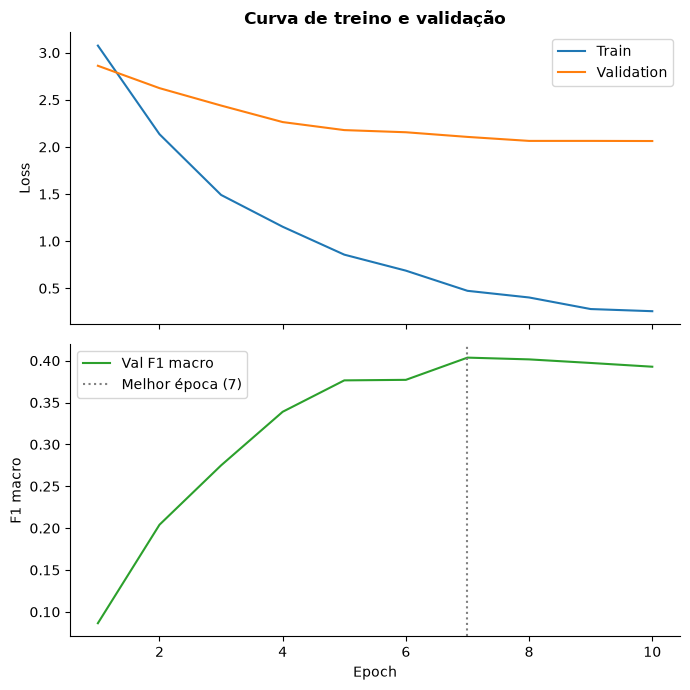

In [9]:
epocas = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# Loss
ax1.plot(epocas, history['train_loss'], label='Train')
ax1.plot(epocas, history['val_loss'], label='Validation')
ax1.set_ylabel('Loss')
ax1.set_title('Curva de treino e validação', fontweight='bold')
ax1.legend()

# F1 de validação
ax2.plot(epocas, history['f1_score'], color='tab:green', label='Val F1 macro')
melhor = int(np.argmax(history['f1_score']))
ax2.axvline(melhor + 1, color='gray', linestyle=':', label=f'Melhor época ({melhor + 1})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('F1 macro')
ax2.legend()

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Avaliação no test_public (checkpoint de melhor F1 no val)

In [10]:
# Recupera o checkpoint escolhido pela melhor F1 macro na validação
pesos_salvos = torch.load('models/best_model_resnet18_parte0.pt', map_location=DEVICE, weights_only=True)
modelo.load_state_dict(pesos_salvos)
previsoes_teste, rotulos_teste = eval_model(modelo, loader_test, criterio, DEVICE)
print('F1 macro (b):', f1_score(rotulos_teste, previsoes_teste, average='macro'))
print('Acurácia (b):', accuracy_score(rotulos_teste, previsoes_teste))
res_b = {'prev': np.array(previsoes_teste), 'rot': np.array(rotulos_teste)}   # guardado: nao depende de variaveis reescritas depois

 F1: 0.4124 |  Teste Loss 1.9687462370433877 
F1 macro (b): 0.4124028533580376
Acurácia (b): 0.43896424167694204


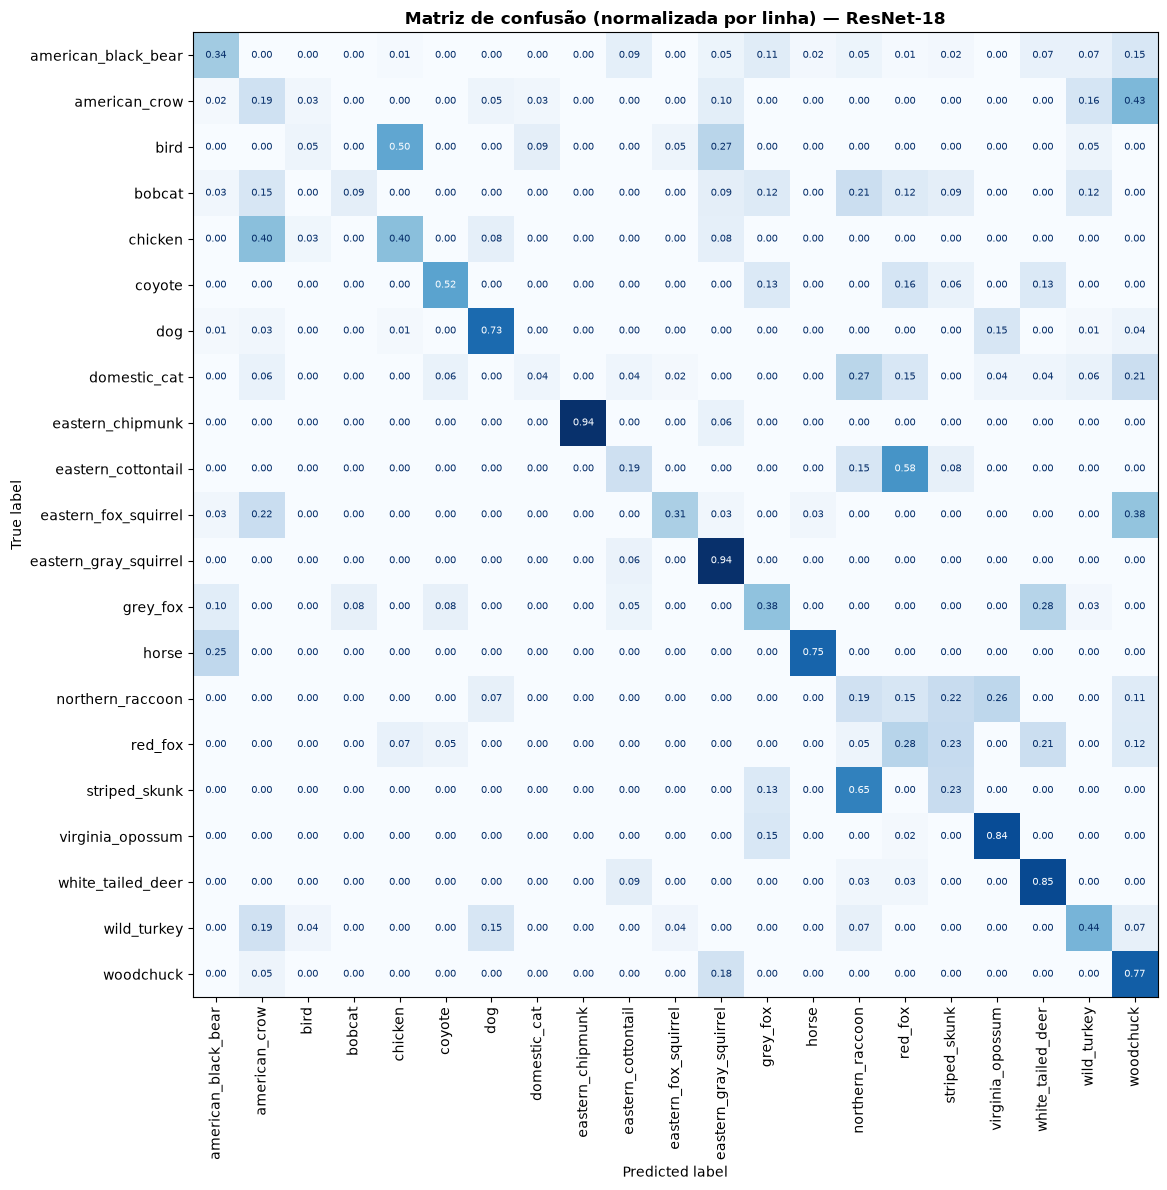

In [11]:
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    res_b['rot'], res_b['prev'],
    labels=range(len(le.classes_)),
    display_labels=le.classes_,
    normalize='true',
    values_format='.2f',
    xticks_rotation=90,
    colorbar=False,
    cmap='Blues',
    ax=ax,
)
for t in ax.texts:
    t.set_fontsize(7)
ax.set_title('Matriz de confusão (normalizada por linha) — ResNet-18', fontweight='bold')
plt.tight_layout()
plt.show()

## (a) CNN pequena do zero

In [12]:
modelo_CNN = CNN_pequena().to(DEVICE)
criterio_cnn = nn.CrossEntropyLoss(weight=pesos_tensor)

history_opcao_a = train_epoch(
    model=modelo_CNN,
    device=DEVICE,
    criterio=criterio_cnn,
    train_loader=loader_train,
    val_loader=loader_val,
    label="cnn_parte0",
    epochs=60,      # suba para 100 se a val ainda estiver melhorando
    lr=1e-3,
)
modelo_CNN.load_state_dict(torch.load('models/best_model_cnn_parte0.pt', map_location=DEVICE, weights_only=True))


previsoes_a, rotulos_a = eval_model(modelo_CNN, loader_test, criterio_cnn, DEVICE)
print("F1 macro:", f1_score(rotulos_a, previsoes_a, average='macro'))
print("Acurácia:", accuracy_score(rotulos_a, previsoes_a))
res_a = {'prev': np.array(previsoes_a), 'rot': np.array(rotulos_a)}

Epoch 1/60 | F1: 0.0148 | Train Loss: 3.371267554873512 | Val Loss: 3.037400953840501 
Epoch 2/60 | F1: 0.0478 | Train Loss: 3.0436442057291666 | Val Loss: 3.006289038327661 
Epoch 3/60 | F1: 0.0782 | Train Loss: 2.9051513671875 | Val Loss: 3.008063288018255 
Epoch 4/60 | F1: 0.1078 | Train Loss: 2.6679143996465773 | Val Loss: 3.0061418892133354 
Epoch 5/60 | F1: 0.1544 | Train Loss: 2.3776361374627974 | Val Loss: 3.366499192643874 
Epoch 6/60 | F1: 0.1341 | Train Loss: 1.9264678955078125 | Val Loss: 3.5128059009514234 
Epoch 7/60 | F1: 0.1625 | Train Loss: 1.801160394577753 | Val Loss: 4.147620777092357 
Epoch 8/60 | F1: 0.1822 | Train Loss: 1.5760888962518602 | Val Loss: 4.437597897973391 
Epoch 9/60 | F1: 0.1867 | Train Loss: 1.5210526239304316 | Val Loss: 4.383951621480508 
Epoch 10/60 | F1: 0.2115 | Train Loss: 1.391158912295387 | Val Loss: 4.272097143796411 
Epoch 11/60 | F1: 0.1855 | Train Loss: 1.0637374877929688 | Val Loss: 5.032492760384437 
Epoch 12/60 | F1: 0.2063 | Train L

## Resumo do piso

Comparação dos dois modelos no mesmo conjunto `test_public`, usando F1 macro e acurácia.

In [13]:
resumo = pd.DataFrame({
    'modelo': ['CNN do zero (a)', 'ResNet-18 ImageNet (b)'],
    'f1_macro': [f1_score(res_a['rot'], res_a['prev'], average='macro'),
                 f1_score(res_b['rot'], res_b['prev'], average='macro')],
    'acuracia': [accuracy_score(res_a['rot'], res_a['prev']),
                 accuracy_score(res_b['rot'], res_b['prev'])],
})
resumo

,modelo,f1_macro,acuracia
0,CNN do zero (a),0.297634,0.344020
1,ResNet-18 ImageNet (b),0.412403,0.438964


### Robustez do piso: a CNN do zero com 3 seeds

Com uma seed só, "CNN (a) > ResNet (b)" não é conclusão: na Parte 2 a própria ResNet varia ±0,05 de F1 entre seeds. Aqui a CNN é repetida com as mesmas 3 seeds da Parte 2 (o piso (b) com 3 seeds está na Parte 2). **Piso oficial do PA = ResNet-18 (b), média de 3 seeds no orçamento 5 (Parte 2).**

In [14]:
from src.autosup import fixar_seed
rows_cnn = []
for seed in (42, 7, 99):
    fixar_seed(seed)
    m = CNN_pequena().to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=pesos_tensor)
    train_epoch(model=m, device=DEVICE, criterio=crit, train_loader=loader_train, val_loader=loader_val,
                label=f'cnn_parte0_seed{seed}', epochs=60, lr=1e-3)
    m.load_state_dict(torch.load(f'models/best_model_cnn_parte0_seed{seed}.pt', map_location=DEVICE, weights_only=True))
    prev, rot = eval_model(m, loader_test, crit, DEVICE)
    rows_cnn.append({'seed': seed, 'f1_macro': f1_score(rot, prev, average='macro'), 'acuracia': accuracy_score(rot, prev)})
df_cnn = pd.DataFrame(rows_cnn)
print(df_cnn.round(4))
print(f"CNN do zero: F1 = {df_cnn.f1_macro.mean():.3f} ± {df_cnn.f1_macro.std():.3f} (3 seeds)")

Epoch 1/60 | F1: 0.0143 | Train Loss: 3.6227943057105656 | Val Loss: 3.0420559420443998 
Epoch 2/60 | F1: 0.0289 | Train Loss: 2.982360549200149 | Val Loss: 2.9998703758315286 
Epoch 3/60 | F1: 0.0516 | Train Loss: 2.7989751906622025 | Val Loss: 3.0236326916383045 
Epoch 4/60 | F1: 0.1075 | Train Loss: 2.541996547154018 | Val Loss: 3.042400095722463 
Epoch 5/60 | F1: 0.1610 | Train Loss: 2.0904275076729912 | Val Loss: 3.3358335589418315 
Epoch 6/60 | F1: 0.2224 | Train Loss: 1.8460751488095237 | Val Loss: 3.795558513981281 
Epoch 7/60 | F1: 0.1506 | Train Loss: 1.703663853236607 | Val Loss: 4.020031617419554 
Epoch 8/60 | F1: 0.1983 | Train Loss: 1.453761945452009 | Val Loss: 3.939439528059251 
Epoch 9/60 | F1: 0.2068 | Train Loss: 1.3766242617652529 | Val Loss: 4.040698967357673 
Epoch 10/60 | F1: 0.1903 | Train Loss: 1.170011247907366 | Val Loss: 4.111849038907797 
Epoch 11/60 | F1: 0.2099 | Train Loss: 1.1331605457124256 | Val Loss: 4.132630603148206 
Epoch 12/60 | F1: 0.2452 | Trai

**Conclusão da Parte 0 (piso).** ResNet-18 do ImageNet com fine-tuning: **F1 macro 0,412, acurácia 0,439** (seed 0; com 3 seeds na Parte 2, 0,391 ± 0,018). CNN pequena do zero: F1 0,298 e acurácia 0,344 (seed 0) e **0,295 ± 0,032 em 3 seeds**. Partir do ImageNet vale ≈ 0,12 de F1 com 105 rótulos. A CNN do zero estagna cedo (F1 de val ≈ 0,24) e a loss de validação sobe de 3,3 para 5–6, sinal claro de sobreajuste. Como o F1 macro pesa cavalo igual a urso, a acurácia sozinha esconderia as classes raras; por isso o piso oficial é a média de 3 seeds da ResNet (b) no orçamento 5.

# Parte 1 — Trilha A: auto-supervisionado (SimCLR)

Continuamos o pré-treino do backbone (ResNet-18) com **SimCLR** sobre as 6.505 imagens do `train`, **sem usar nenhum rótulo** (só os ids dos arquivos). Depois avaliamos com os 105 rótulos de `rotulos_5.csv` de duas formas: **avaliação linear** (encoder congelado) e **fine-tuning**. `val` escolhe C / checkpoint; `test_public` só reporta.

Toda a lógica está em `src/autosup.py`; aqui só orquestramos.

In [15]:
import cv2
from src.autosup import (criar_augment_simclr, criar_encoder, pretreino_simclr, avaliacao_linear,
                         finetune_e_testa, listar_ids, desnormalizar, contar_parametros, criar_classificador, fixar_seed)

AMP = True
LADO_SSL = 224        # mesmo lado da avaliacao (antes: 160, descasado com os 224 do fine-tuning/avaliacao)
MAX_IMGS = None
EPOCAS_SSL = 20       # antes: 3 (nao convergia). Se o tempo apertar: reduza, mas nao abaixo de ~10
EPOCAS_FT = 15        # mesmo numero de epocas para piso e metodo, na Parte 1 e na Parte 2
RAIZ_TRAIN = "pa3_dados/images/train"

# --- Conjunto de 105 rotulos EXPLICITO. O fine-tuning e a avaliacao linear usam SO estes objetos;
# --- antes dependiam de `loader_train`/`pesos_tensor` globais, que o loop da Parte 2 sobrescrevia (orcamento 20).
df_105 = df_treino.copy()
assert len(df_105) == 105 and df_105['label'].nunique() == 21, 'df_treino nao e o rotulos_5.csv'
loader_105 = DataLoader(DatasetTrap(df=df_105, raiz=RAIZ_TRAIN, augment=transform_treino), batch_size=16, shuffle=True)
loader_105_feat = DataLoader(DatasetTrap(df=df_105, raiz=RAIZ_TRAIN, augment=transform_val), batch_size=16, shuffle=False)
pesos_105 = torch.tensor(compute_class_weight('balanced', classes=np.unique(df_105['label']), y=df_105['label'].values),
                         dtype=torch.float32, device=DEVICE)
assert len(loader_105.dataset) == 105 and len(loader_105_feat.dataset) == 105
print('Rotulos no fine-tuning da Parte 1:', len(loader_105.dataset))
print('Parametros ResNet-18 (sem fc):', contar_parametros(criar_encoder('imagenet')))

Rotulos no fine-tuning da Parte 1: 105
Parametros ResNet-18 (sem fc): 11176512


## 1. Pré-treino SimCLR (aumentação padrão: crop com `scale=(0.2, 1.0)`)

Dois pré-treinos, ambos no `train` inteiro: partindo do **ImageNet** e partindo de pesos **aleatórios**.

In [16]:
enc = criar_encoder('imagenet')
hist_ssl_imagenet = pretreino_simclr(enc, RAIZ_TRAIN, criar_augment_simclr(scale=(0.2, 1.0), lado=LADO_SSL), DEVICE,
                                     label='imagenet_s02', epocas=EPOCAS_SSL, amp=AMP, max_imgs=MAX_IMGS)

[imagenet_s02] Epoch 1/20 | NT-Xent: 4.1102 | 205s
[imagenet_s02] Epoch 2/20 | NT-Xent: 3.8540 | 143s
[imagenet_s02] Epoch 3/20 | NT-Xent: 3.7986 | 147s
[imagenet_s02] Epoch 4/20 | NT-Xent: 3.7726 | 144s
[imagenet_s02] Epoch 5/20 | NT-Xent: 3.7441 | 143s
[imagenet_s02] Epoch 6/20 | NT-Xent: 3.7284 | 144s
[imagenet_s02] Epoch 7/20 | NT-Xent: 3.7159 | 147s
[imagenet_s02] Epoch 8/20 | NT-Xent: 3.7050 | 159s
[imagenet_s02] Epoch 9/20 | NT-Xent: 3.7005 | 160s
[imagenet_s02] Epoch 10/20 | NT-Xent: 3.6918 | 158s
[imagenet_s02] Epoch 11/20 | NT-Xent: 3.6829 | 159s
[imagenet_s02] Epoch 12/20 | NT-Xent: 3.6805 | 159s
[imagenet_s02] Epoch 13/20 | NT-Xent: 3.6759 | 161s
[imagenet_s02] Epoch 14/20 | NT-Xent: 3.6726 | 161s
[imagenet_s02] Epoch 15/20 | NT-Xent: 3.6686 | 160s
[imagenet_s02] Epoch 16/20 | NT-Xent: 3.6668 | 159s
[imagenet_s02] Epoch 17/20 | NT-Xent: 3.6627 | 162s
[imagenet_s02] Epoch 18/20 | NT-Xent: 3.6619 | 161s
[imagenet_s02] Epoch 19/20 | NT-Xent: 3.6621 | 160s
[imagenet_s02] Epoch 

In [17]:
enc = criar_encoder('aleatorio')
hist_ssl_aleatorio = pretreino_simclr(enc, RAIZ_TRAIN, criar_augment_simclr(scale=(0.2, 1.0), lado=LADO_SSL), DEVICE,
                                      label='aleatorio_s02', epocas=EPOCAS_SSL, lr=1e-3, amp=AMP, max_imgs=MAX_IMGS)

[aleatorio_s02] Epoch 1/20 | NT-Xent: 4.8041 | 214s
[aleatorio_s02] Epoch 2/20 | NT-Xent: 4.5280 | 214s
[aleatorio_s02] Epoch 3/20 | NT-Xent: 4.4522 | 147s
[aleatorio_s02] Epoch 4/20 | NT-Xent: 4.3515 | 150s
[aleatorio_s02] Epoch 5/20 | NT-Xent: 4.2713 | 144s
[aleatorio_s02] Epoch 6/20 | NT-Xent: 4.2211 | 134s
[aleatorio_s02] Epoch 7/20 | NT-Xent: 4.1695 | 126s
[aleatorio_s02] Epoch 8/20 | NT-Xent: 4.1320 | 126s
[aleatorio_s02] Epoch 9/20 | NT-Xent: 4.0848 | 127s
[aleatorio_s02] Epoch 10/20 | NT-Xent: 4.0673 | 126s
[aleatorio_s02] Epoch 11/20 | NT-Xent: 4.0277 | 128s
[aleatorio_s02] Epoch 12/20 | NT-Xent: 4.0024 | 126s
[aleatorio_s02] Epoch 13/20 | NT-Xent: 3.9844 | 128s
[aleatorio_s02] Epoch 14/20 | NT-Xent: 3.9553 | 127s
[aleatorio_s02] Epoch 15/20 | NT-Xent: 3.9423 | 134s
[aleatorio_s02] Epoch 16/20 | NT-Xent: 3.9257 | 134s
[aleatorio_s02] Epoch 17/20 | NT-Xent: 3.9144 | 134s
[aleatorio_s02] Epoch 18/20 | NT-Xent: 3.8991 | 135s
[aleatorio_s02] Epoch 19/20 | NT-Xent: 3.9010 | 137s
[a

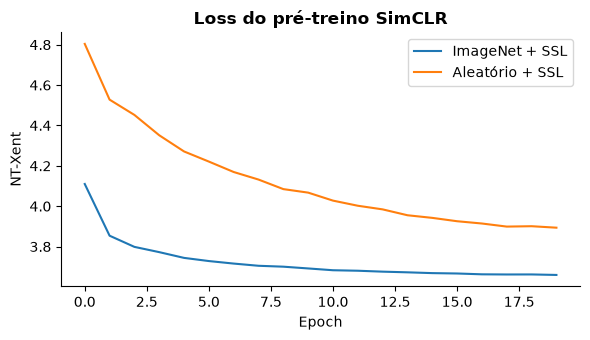

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist_ssl_imagenet['loss'], label='ImageNet + SSL')
ax.plot(hist_ssl_aleatorio['loss'], label='Aleatório + SSL')
ax.set_xlabel('Epoch'); ax.set_ylabel('NT-Xent'); ax.set_title('Loss do pré-treino SimCLR', fontweight='bold')
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 2. Avaliação linear com três backbones lado a lado

Encoder congelado + regressão logística nos 105 rótulos (C escolhido no `val`). Backbones: **ImageNet puro**, **ImageNet + SSL**, **aleatório + SSL**.

In [19]:
backbones = {
    'ImageNet puro':   criar_encoder('imagenet'),
    'ImageNet + SSL':  criar_encoder('imagenet', 'models/simclr_imagenet_s02.pt'),
    'Aleatório + SSL': criar_encoder('aleatorio', 'models/simclr_aleatorio_s02.pt'),
}
res_linear = {nome: avaliacao_linear(e, loader_105_feat, loader_val, loader_test, DEVICE)
              for nome, e in backbones.items()}
tab_linear = pd.DataFrame({n: {'C (val)': r['C'], 'F1 macro val': r['f1_val'],
                               'F1 macro test': r['f1'], 'Acurácia test': r['acc']}
                           for n, r in res_linear.items()}).T
tab_linear

,C (val),F1 macro val,F1 macro test,Acurácia test
ImageNet puro,10.00,0.410628,0.417583,0.472256
ImageNet + SSL,0.01,0.344265,0.409528,0.448829
Aleatório + SSL,10.00,0.290082,0.305790,0.334155


## 3. Experimento de aumentação: o crop do SimCLR

**Problema.** Com o animal ocupando ~2% do quadro, um `RandomResizedCrop` com `scale=(0.2, 1.0)` muitas vezes gera uma view **sem animal**. Nesse caso o par positivo é (fundo, fundo), e a loss NT-Xent aproxima representações de *fundo* — justamente o atalho que a Parte 3 investiga.

**Mudança testada.** Aumentar o piso do crop: `scale=(0.5, 1.0)`. Com crops grandes, é bem mais provável que as duas views contenham o animal, então o que é aproximado passa a ser mais "animal" e menos "fundo". Primeiro, olhamos as views; depois medimos.

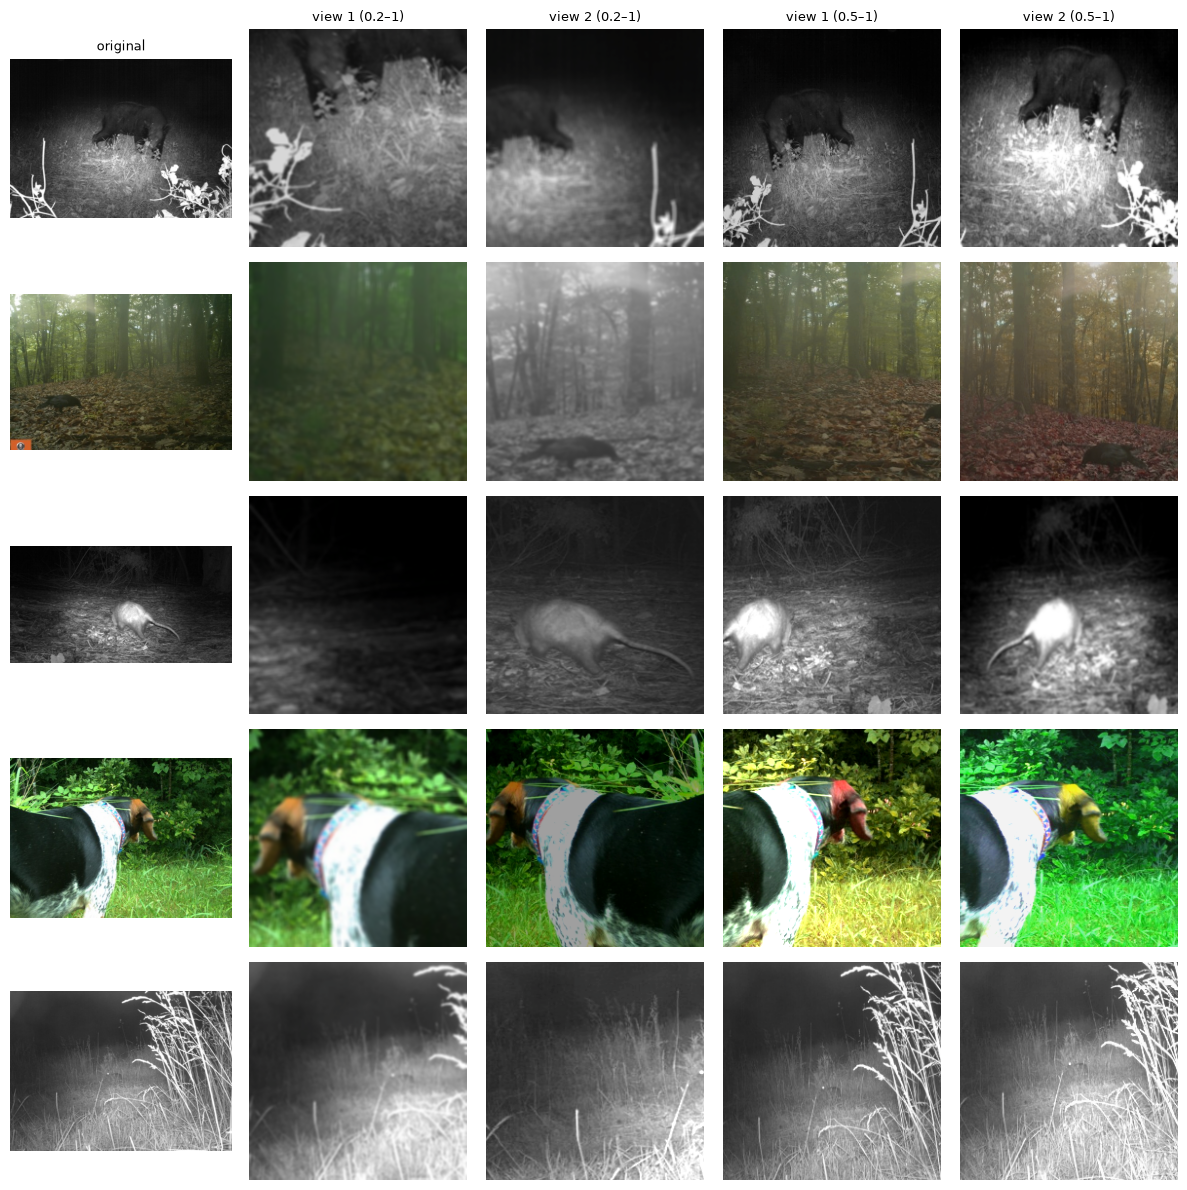

In [20]:
import random as _r
aug_a, aug_b = criar_augment_simclr((0.2, 1.0)), criar_augment_simclr((0.5, 1.0))
ids_amostra = _r.Random(1).sample(listar_ids(RAIZ_TRAIN), 5)

fig, axes = plt.subplots(len(ids_amostra), 5, figsize=(12, 2.4 * len(ids_amostra)))
for i, iid in enumerate(ids_amostra):
    img = cv2.cvtColor(cv2.imread(f'{RAIZ_TRAIN}/{iid}.jpg'), cv2.COLOR_BGR2RGB)
    vistas = [img] + [desnormalizar(a(image=img)['image']) for a in (aug_a, aug_a, aug_b, aug_b)]
    for j, v in enumerate(vistas):
        axes[i, j].imshow(v); axes[i, j].axis('off')
for j, t in enumerate(['original', 'view 1 (0.2–1)', 'view 2 (0.2–1)', 'view 1 (0.5–1)', 'view 2 (0.5–1)']):
    axes[0, j].set_title(t, fontsize=9)
plt.tight_layout(); plt.show()

In [21]:
enc = criar_encoder('imagenet')
hist_ssl_imagenet_s05 = pretreino_simclr(enc, RAIZ_TRAIN, criar_augment_simclr(scale=(0.5, 1.0), lado=LADO_SSL), DEVICE,
                                         label='imagenet_s05', epocas=EPOCAS_SSL, amp=AMP, max_imgs=MAX_IMGS)

[imagenet_s05] Epoch 1/20 | NT-Xent: 3.9799 | 162s
[imagenet_s05] Epoch 2/20 | NT-Xent: 3.7563 | 132s
[imagenet_s05] Epoch 3/20 | NT-Xent: 3.7097 | 133s
[imagenet_s05] Epoch 4/20 | NT-Xent: 3.6840 | 132s
[imagenet_s05] Epoch 5/20 | NT-Xent: 3.6690 | 133s
[imagenet_s05] Epoch 6/20 | NT-Xent: 3.6573 | 139s
[imagenet_s05] Epoch 7/20 | NT-Xent: 3.6525 | 133s
[imagenet_s05] Epoch 8/20 | NT-Xent: 3.6459 | 131s
[imagenet_s05] Epoch 9/20 | NT-Xent: 3.6416 | 132s
[imagenet_s05] Epoch 10/20 | NT-Xent: 3.6395 | 131s
[imagenet_s05] Epoch 11/20 | NT-Xent: 3.6342 | 131s
[imagenet_s05] Epoch 12/20 | NT-Xent: 3.6329 | 134s
[imagenet_s05] Epoch 13/20 | NT-Xent: 3.6300 | 136s
[imagenet_s05] Epoch 14/20 | NT-Xent: 3.6262 | 131s
[imagenet_s05] Epoch 15/20 | NT-Xent: 3.6266 | 131s
[imagenet_s05] Epoch 16/20 | NT-Xent: 3.6259 | 132s
[imagenet_s05] Epoch 17/20 | NT-Xent: 3.6235 | 133s
[imagenet_s05] Epoch 18/20 | NT-Xent: 3.6226 | 131s
[imagenet_s05] Epoch 19/20 | NT-Xent: 3.6222 | 136s
[imagenet_s05] Epoch 

In [22]:
res_linear['ImageNet + SSL (crop 0.5–1)'] = avaliacao_linear(
    criar_encoder('imagenet', 'models/simclr_imagenet_s05.pt'), loader_105_feat, loader_val, loader_test, DEVICE)
pd.DataFrame({n: {'F1 macro val': res_linear[n]['f1_val'], 'F1 macro test': res_linear[n]['f1'],
                  'Acurácia test': res_linear[n]['acc']}
              for n in ['ImageNet puro', 'ImageNet + SSL', 'ImageNet + SSL (crop 0.5–1)']}).T

,F1 macro val,F1 macro test,Acurácia test
ImageNet puro,0.410628,0.417583,0.472256
ImageNet + SSL,0.344265,0.409528,0.448829
ImageNet + SSL (crop 0.5–1),0.380846,0.433808,0.473490


In [23]:
# Qual pre-treino SSL segue para o fine-tuning e para a Parte 2? Escolha pelo F1 de VAL da avaliacao linear.
cand_ssl = {'ImageNet + SSL': 'models/simclr_imagenet_s02.pt',
            'ImageNet + SSL (crop 0.5–1)': 'models/simclr_imagenet_s05.pt'}
SSL_NOME = max(cand_ssl, key=lambda n: res_linear[n]['f1_val'])
SSL_CKPT = cand_ssl[SSL_NOME]
print('Backbone SSL escolhido (F1 val):', SSL_NOME, '->', SSL_CKPT)

Backbone SSL escolhido (F1 val): ImageNet + SSL (crop 0.5–1) -> models/simclr_imagenet_s05.pt


**O que a rede aproxima quando o crop não contém o animal.** Se as duas views de um par são pedaços de fundo, a única coisa que elas têm em comum é o fundo: textura, iluminação, infravermelho × cor, vegetação, ou seja, a *câmera/cena*. Para baixar a NT-Xent, a rede aprende a reconhecer a cena, e as features do animal não recebem sinal nenhum nesse par. É exatamente o atalho investigado na Parte 3.

**Mudança testada:** piso do crop de 0,2 para 0,5. **Limitações a declarar:** (i) o pacote não tem caixas, então a fração de views sem animal *não foi medida*; (ii) crop maior também torna a tarefa pretexto mais fácil e afasta menos os pesos do ImageNet, então o efeito não é isolado; (iii) uma seed só. O resultado numérico é impresso na célula abaixo, para o texto não ficar desencontrado dos números.

In [24]:
a, b, base = res_linear['ImageNet + SSL'], res_linear['ImageNet + SSL (crop 0.5–1)'], res_linear['ImageNet puro']
print(f"Avaliação linear, F1 macro (val | test):")
print(f"  ImageNet puro          : {base['f1_val']:.3f} | {base['f1']:.3f}")
print(f"  SSL, crop 0.2–1        : {a['f1_val']:.3f} | {a['f1']:.3f}")
print(f"  SSL, crop 0.5–1        : {b['f1_val']:.3f} | {b['f1']:.3f}")
print(f"Efeito do crop (0.5 menos 0.2): val {b['f1_val']-a['f1_val']:+.3f} | test {b['f1']-a['f1']:+.3f}")
print("Só trate como efeito real se for maior que o desvio entre seeds medido na Parte 2 (uma seed aqui).")

Avaliação linear, F1 macro (val | test):
  ImageNet puro          : 0.411 | 0.418
  SSL, crop 0.2–1        : 0.344 | 0.410
  SSL, crop 0.5–1        : 0.381 | 0.434
Efeito do crop (0.5 menos 0.2): val +0.037 | test +0.024
Só trate como efeito real se for maior que o desvio entre seeds medido na Parte 2 (uma seed aqui).


**Conclusão do experimento de aumentação.** Subir o piso do crop de 0,2 para 0,5 deu **+0,037 de F1 no val e +0,024 no test** na avaliação linear (uma seed). Isso é coerente com a hipótese, mas **não a prova**: (i) não há caixas, então a fração de views sem animal não foi medida; (ii) a loss final do SimCLR com crop 0,5 é menor (3,62 contra 3,66), isto é, a tarefa pretexto ficou mais fácil e o encoder se afastou menos do ImageNet, o que também explicaria a melhora; (iii) o efeito é do tamanho do ruído entre seeds. O que a rede aprende a aproximar quando o crop não tem o animal é o **cenário** (iluminação, vegetação, tipo de foto), que é justamente o atalho que a Parte 3 investiga. O crop 0,5 foi o escolhido para o restante pelo F1 de val, não pelo test.

## 4. Fine-tuning com os 105 rótulos

Mesmo protocolo da Parte 0 (b): checkpoint pela melhor F1 macro no `val`, métricas no `test_public`, **sempre com os 105 rótulos de `rotulos_5.csv`** (verificado por `assert` na configuração). "ImageNet puro" é o próprio piso. Os dois crops de SSL (0,2–1 e 0,5–1) já foram comparados na avaliação linear; aqui segue o escolhido pelo F1 de val.

In [25]:
configs_ft = {
    'ImageNet puro (piso)': dict(inicializacao='imagenet',  state_path=None,     label='ft_imagenet_puro', epocas=EPOCAS_FT, lr=1e-4),
    f'{SSL_NOME}':          dict(inicializacao='imagenet',  state_path=SSL_CKPT, label='ft_imagenet_ssl',  epocas=EPOCAS_FT, lr=1e-4),
    'Aleatório + SSL':      dict(inicializacao='aleatorio', state_path='models/simclr_aleatorio_s02.pt',
                                 label='ft_aleatorio_ssl', epocas=2 * EPOCAS_FT, lr=3e-4),
}
res_ft = {nome: finetune_e_testa(loader_train=loader_105, loader_val=loader_val, loader_test=loader_test,
                                 pesos_tensor=pesos_105, device=DEVICE, seed=0, **cfg)
          for nome, cfg in configs_ft.items()}
tab_ft = pd.DataFrame({n: {'F1 macro val (melhor)': max(r['hist']['f1_score']), 'F1 macro test': r['f1'], 'Acurácia test': r['acc']}
                       for n, r in res_ft.items()}).T
tab_ft

Epoch 1/15 | F1: 0.0971 | Train Loss: 3.067045665922619 | Val Loss: 2.805696695157797 
Epoch 2/15 | F1: 0.2143 | Train Loss: 2.0921126592726935 | Val Loss: 2.547381108350093 
Epoch 3/15 | F1: 0.2792 | Train Loss: 1.4928530738467263 | Val Loss: 2.3803738131381498 
Epoch 4/15 | F1: 0.3347 | Train Loss: 1.1459632510230655 | Val Loss: 2.220072226949257 
Epoch 5/15 | F1: 0.3621 | Train Loss: 0.836177498953683 | Val Loss: 2.161494793278156 
Epoch 6/15 | F1: 0.3715 | Train Loss: 0.6783201671781994 | Val Loss: 2.1243334477490716 
Epoch 7/15 | F1: 0.4106 | Train Loss: 0.505856177920387 | Val Loss: 2.0753942810662904 
Epoch 8/15 | F1: 0.4105 | Train Loss: 0.3502321515764509 | Val Loss: 2.060147729250464 
Epoch 9/15 | F1: 0.4450 | Train Loss: 0.3048462640671503 | Val Loss: 2.0366907403020575 
Epoch 10/15 | F1: 0.3972 | Train Loss: 0.21126434689476375 | Val Loss: 2.049254313553914 
Epoch 11/15 | F1: 0.4070 | Train Loss: 0.17637765066964287 | Val Loss: 2.0857608908473857 
Epoch 12/15 | F1: 0.4251 |

,F1 macro val (melhor),F1 macro test,Acurácia test
ImageNet puro (piso),0.444978,0.456739,0.471023
ImageNet + SSL (crop 0.5–1),0.442649,0.396649,0.450062
Aleatório + SSL,0.302409,0.309419,0.353884


### Resumo da Parte 1 (Trilha A)

Valores desta execução (105 rótulos, SimCLR de 20 épocas a 224 px):

| Backbone | Linear F1 val | Linear F1 test | Fine-tuning F1 test (seed 0) |
|---|---|---|---|
| ImageNet puro (piso) | 0,411 | 0,418 | 0,457 |
| ImageNet + SSL (crop 0,2–1) | 0,344 | 0,410 | — |
| ImageNet + SSL (crop 0,5–1) | 0,381 | 0,434 | 0,397 |
| Aleatório + SSL | 0,290 | 0,306 | 0,309 |

**O pré-treino no domínio vale alguma coisa em cima do ImageNet?** Nesta configuração, **não de forma demonstrável**. Na avaliação linear o ImageNet puro e o ImageNet + SSL ficam empatados no test (0,418 contra 0,410 e 0,434, diferenças dentro do ruído de uma seed) e o ImageNet puro é melhor no val (0,411 contra 0,344 e 0,381). No fine-tuning de seed 0 o piso foi melhor que o SSL (0,457 contra 0,397). A Parte 2 (3 seeds) mostra o contrário no orçamento 5, e a diferença é pequena; ver a conclusão da Parte 2. O backbone aleatório + SSL fica em ≈ 0,31: 20 épocas em 6.505 imagens não bastam para substituir as features do ImageNet. A loss do SimCLR estabiliza (3,66 com ImageNet), então o pré-treino convergiu para o que esse recipe consegue; mais épocas provavelmente mudariam pouco.

**Quanto da distância piso → teto (0,686) o SimCLR recupera?** Cerca de **10%** no orçamento 5 (piso 0,391, SimCLR 0,419, teto 0,686), e isso mesmo sem ser claramente maior que o ruído entre seeds.

## Parte 2

In [26]:
import os
os.makedirs('models', exist_ok=True)
TETO = 0.686                                     # ResNet-18 com todos os rotulos (enunciado)
ORCAMENTOS = {1: [42], 5: [42, 7, 99], 20: [42]}  # 5 rotulos/classe: 3 seeds; os outros: 1
METODOS = {'piso (b)': (None, 'piso'), 'SimCLR (Trilha A)': (SSL_CKPT, 'simclr')}


def rodar(ckpt, tag, orc, seed):
    """Tudo local: nenhum estado global (loader/pesos) vaza entre execucoes ou para outras partes."""
    df_o = pd.read_csv(f'pa3_dados/labels/rotulos_{orc}.csv')
    df_o['label'] = le.transform(df_o['label'])
    fixar_seed(seed)
    loader = DataLoader(DatasetTrap(df=df_o, raiz=RAIZ_TRAIN, augment=transform_treino), batch_size=16, shuffle=True)
    w = torch.tensor(compute_class_weight('balanced', classes=np.unique(df_o['label']), y=df_o['label'].values),
                     dtype=torch.float32, device=DEVICE)
    label = f'p2_{tag}_orc{orc}_seed{seed}'
    r = finetune_e_testa('imagenet', ckpt, loader, loader_val, loader_test, w, DEVICE, label=label,
                         epocas=EPOCAS_FT, lr=1e-4, seed=seed)
    return label, len(df_o), r


resultados_gerais, preds, runs = [], {}, []
for orc, seeds in ORCAMENTOS.items():
    for seed in seeds:
        for metodo, (ckpt, tag) in METODOS.items():
            label, n_rot, r = rodar(ckpt, tag, orc, seed)
            resultados_gerais.append({'metodo': metodo, 'orcamento': orc, 'seed': seed,
                                      'f1_macro': r['f1'], 'acuracia': r['acc']})
            preds[(metodo, orc, seed)] = {'prev': np.array(r['prev']), 'rot': np.array(r['rot'])}
            runs.append({'metodo': metodo, 'orcamento': orc, 'seed': seed, 'n_rotulos': n_rot,
                         'f1_val': max(r['hist']['f1_score']), 'checkpoint': f'models/best_model_{label}.pt'})

df = pd.DataFrame(resultados_gerais)
df.to_csv('curva_orcamento.csv', index=False)          # colunas exigidas: metodo, orcamento, seed, f1_macro, acuracia
df_runs = pd.DataFrame(runs)                            # extras (val, checkpoint) para escolher o modelo final
df_runs.to_csv('execucoes_parte2.csv', index=False)
assert (df_runs.groupby('orcamento').n_rotulos.first().to_dict() == {1: 21, 5: 105, 20: 420}), 'orcamento errado'
df

Epoch 1/15 | F1: 0.0298 | Train Loss: 3.3501775832403276 | Val Loss: 3.2223063553913986 
Epoch 2/15 | F1: 0.0382 | Train Loss: 2.2304880051385787 | Val Loss: 3.125962663405012 
Epoch 3/15 | F1: 0.0460 | Train Loss: 1.7036176409040178 | Val Loss: 3.0268237425549196 
Epoch 4/15 | F1: 0.1117 | Train Loss: 1.3608406611851283 | Val Loss: 2.950070824953589 
Epoch 5/15 | F1: 0.1115 | Train Loss: 1.081412633260091 | Val Loss: 2.875610955870978 
Epoch 6/15 | F1: 0.1301 | Train Loss: 0.7929217928931827 | Val Loss: 2.8206572579865408 
Epoch 7/15 | F1: 0.1467 | Train Loss: 0.7300125303722563 | Val Loss: 2.7884464075069615 
Epoch 8/15 | F1: 0.1838 | Train Loss: 0.5424526759556362 | Val Loss: 2.760341833133509 
Epoch 9/15 | F1: 0.1879 | Train Loss: 0.4508047103881836 | Val Loss: 2.7393653794090347 
Epoch 10/15 | F1: 0.2034 | Train Loss: 0.3955782027471633 | Val Loss: 2.726091743695854 
Epoch 11/15 | F1: 0.2232 | Train Loss: 0.2787988526480539 | Val Loss: 2.711023009649598 
Epoch 12/15 | F1: 0.2123 |

,metodo,orcamento,seed,f1_macro,acuracia
0,piso (b),1,42,0.212226,0.220715
1,SimCLR (Trilha A),1,42,0.216764,0.217016
2,piso (b),5,42,0.408794,0.431566
3,SimCLR (Trilha A),5,42,0.425810,0.453761
4,piso (b),5,7,0.390454,0.426634
5,SimCLR (Trilha A),5,7,0.428152,0.452528
6,piso (b),5,99,0.372830,0.424168
7,SimCLR (Trilha A),5,99,0.402449,0.458693
8,piso (b),20,42,0.610900,0.652281
9,SimCLR (Trilha A),20,42,0.600584,0.622688


mean     std  count
metodo            orcamento                       
SimCLR (Trilha A) 1          0.2168  0.0000      1
                  5          0.4188  0.0142      3
                  20         0.6006  0.0000      1
piso (b)          1          0.2122  0.0000      1
                  5          0.3907  0.0180      3
                  20         0.6109  0.0000      1

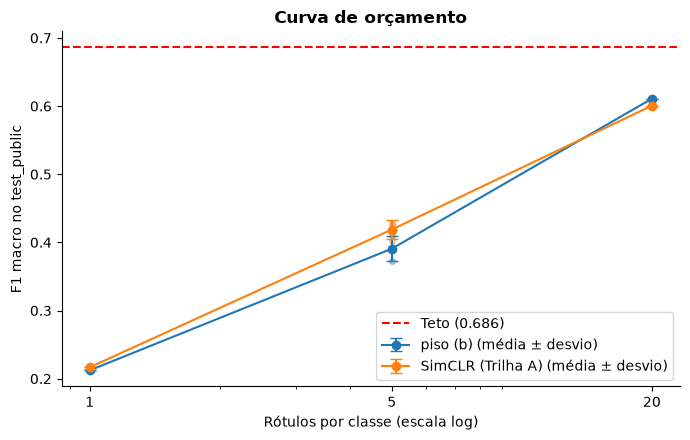

In [27]:
# Media ± desvio (ddof=1) por metodo e orcamento; no orcamento 5 sao 3 seeds
tab = df.groupby(['metodo', 'orcamento']).f1_macro.agg(['mean', 'std', 'count']).round(4)
tab['std'] = tab['std'].fillna(0.0)
display(tab)

fig, ax = plt.subplots(figsize=(7, 4.5))
for metodo, cor in zip(['piso (b)', 'SimCLR (Trilha A)'], ['tab:blue', 'tab:orange']):
    g = df[df.metodo == metodo]
    m = g.groupby('orcamento').f1_macro.agg(['mean', 'std']).fillna(0.0)
    ax.errorbar(m.index, m['mean'], yerr=m['std'], marker='o', capsize=4, color=cor, label=f'{metodo} (média ± desvio)')
    ax.scatter(g.orcamento, g.f1_macro, color=cor, alpha=0.35, s=18)   # cada seed
ax.axhline(TETO, color='red', linestyle='--', label=f'Teto ({TETO})')
ax.set_xscale('log'); ax.set_xticks(list(ORCAMENTOS)); ax.set_xticklabels(list(ORCAMENTOS))
ax.set_xlabel('Rótulos por classe (escala log)'); ax.set_ylabel('F1 macro no test_public')
ax.set_title('Curva de orçamento', fontweight='bold'); ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); os.makedirs('figuras', exist_ok=True); plt.savefig('figuras/curva_orcamento.png', dpi=150); plt.show()

,classe,suporte_test,F1 piso,F1 SimCLR,ganho
0,eastern_cottontail,26,0.000,0.517,0.517
1,red_fox,43,0.243,0.455,0.212
2,white_tailed_deer,33,0.623,0.820,0.197
3,striped_skunk,31,0.310,0.478,0.167
4,northern_raccoon,27,0.216,0.307,0.091
5,chicken,60,0.420,0.487,0.067
6,american_crow,63,0.248,0.305,0.056
7,bird,22,0.064,0.089,0.025
8,virginia_opossum,55,0.837,0.861,0.023
9,coyote,31,0.545,0.554,0.009


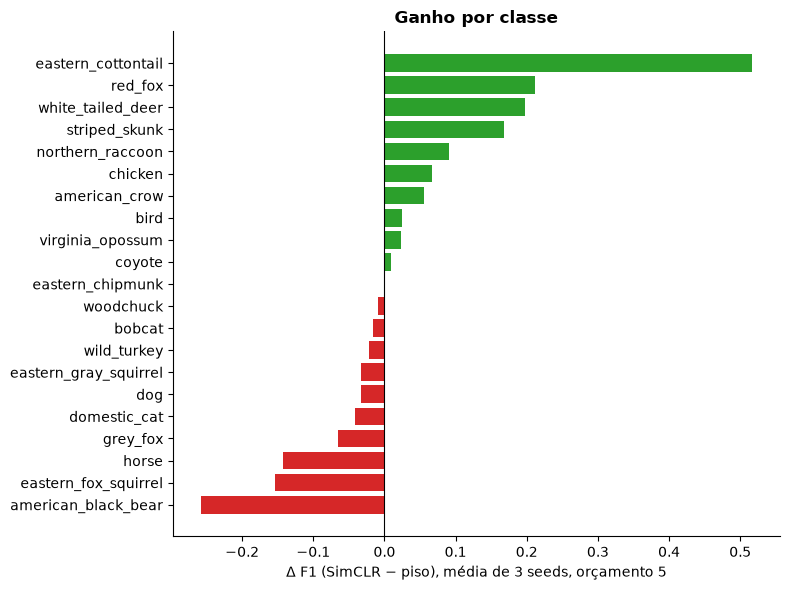

Classes que mais ganharam : eastern_cottontail, red_fox, white_tailed_deer
Sem ganho (Δ <= 0)        : eastern_chipmunk, woodchuck, bobcat, wild_turkey, eastern_gray_squirrel, dog, domestic_cat, grey_fox, horse, eastern_fox_squirrel, american_black_bear
Atenção: horse tem 4 imagens no test_public; um acerto muda o F1 dela em muito. Não conclua nada só por ela.


In [28]:
# Ganho por classe no orcamento 5: F1 por classe medio nas 3 seeds, metodo menos piso
from sklearn.metrics import f1_score as _f1
seeds5 = ORCAMENTOS[5]
def f1_cls(metodo):
    return np.mean([_f1(preds[(metodo, 5, s)]['rot'], preds[(metodo, 5, s)]['prev'],
                        labels=range(len(le.classes_)), average=None, zero_division=0) for s in seeds5], axis=0)
rot_ref = preds[('piso (b)', 5, seeds5[0])]['rot']
ganho = pd.DataFrame({'classe': le.classes_, 'suporte_test': np.bincount(rot_ref, minlength=len(le.classes_)),
                      'F1 piso': f1_cls('piso (b)'), 'F1 SimCLR': f1_cls('SimCLR (Trilha A)')})
ganho['ganho'] = ganho['F1 SimCLR'] - ganho['F1 piso']
ganho = ganho.sort_values('ganho', ascending=False).reset_index(drop=True)
display(ganho.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(ganho.classe[::-1], ganho.ganho[::-1], color=['tab:green' if g > 0 else 'tab:red' for g in ganho.ganho[::-1]])
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('Δ F1 (SimCLR − piso), média de 3 seeds, orçamento 5')
ax.set_title('Ganho por classe', fontweight='bold'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('figuras/ganho_por_classe.png', dpi=150); plt.show()

print('Classes que mais ganharam :', ', '.join(ganho.classe[:3]))
print('Sem ganho (Δ <= 0)        :', ', '.join(ganho.classe[ganho.ganho <= 0]) or '(nenhuma)')
print('Atenção: horse tem 4 imagens no test_public; um acerto muda o F1 dela em muito. Não conclua nada só por ela.')

In [29]:
# Resumo da Trilha A: piso -> metodo -> teto, calculado dos numeros acima
g5 = df[df.orcamento == 5].pivot(index='seed', columns='metodo', values='f1_macro')
piso5, met5 = g5['piso (b)'].mean(), g5['SimCLR (Trilha A)'].mean()
d = g5['SimCLR (Trilha A)'] - g5['piso (b)']
print(f"Orçamento 5 (3 seeds): piso {piso5:.3f} ± {g5['piso (b)'].std():.3f} | SimCLR {met5:.3f} ± {g5['SimCLR (Trilha A)'].std():.3f}")
print(f"Ganho pareado por seed: {d.round(3).tolist()} | média {d.mean():+.3f} ± {d.std():.3f}")
print(f"Distância piso→teto: {TETO - piso5:.3f}; recuperada pelo SimCLR: {(met5 - piso5) / (TETO - piso5):.0%}")
for orc in (1, 20):
    r = df[df.orcamento == orc].set_index('metodo').f1_macro
    print(f"Orçamento {orc}: piso {r['piso (b)']:.3f} | SimCLR {r['SimCLR (Trilha A)']:.3f} | Δ {r['SimCLR (Trilha A)'] - r['piso (b)']:+.3f} (1 seed)")
print()
print('Fine-tuning da Parte 1 (105 rótulos, seed 0, val escolhe checkpoint):')
display(tab_ft.round(3))

Orçamento 5 (3 seeds): piso 0.391 ± 0.018 | SimCLR 0.419 ± 0.014
Ganho pareado por seed: [0.038, 0.017, 0.03] | média +0.028 ± 0.010
Distância piso→teto: 0.295; recuperada pelo SimCLR: 10%
Orçamento 1: piso 0.212 | SimCLR 0.217 | Δ +0.005 (1 seed)
Orçamento 20: piso 0.611 | SimCLR 0.601 | Δ -0.010 (1 seed)

Fine-tuning da Parte 1 (105 rótulos, seed 0, val escolhe checkpoint):


,F1 macro val (melhor),F1 macro test,Acurácia test
ImageNet puro (piso),0.445,0.457,0.471
ImageNet + SSL (crop 0.5–1),0.443,0.397,0.450
Aleatório + SSL,0.302,0.309,0.354


### Conclusões da Parte 2

**Curva.** O número de rótulos domina: o F1 sobe de ≈ 0,21 (1 por classe) para ≈ 0,39–0,42 (5) e ≈ 0,60–0,61 (20). Com 20 rótulos por classe o piso já chega a 89% do teto (0,611 contra 0,686). O método quase não muda a curva: Δ = +0,005 no orçamento 1 e **−0,010 no orçamento 20** (uma seed cada; não afirmo ganho nem perda ali).

**Orçamento 5 (3 seeds).** Piso 0,391 ± 0,018; SimCLR 0,419 ± 0,014; ganho pareado por seed de +0,038, +0,017 e +0,030 (média +0,028). Isso recupera ≈ 10% da distância até o teto. **Ressalva importante:** no fine-tuning da Parte 1 (seed 0) o piso (0,457) superou o SimCLR (0,397) por 0,06. Esse piso está bem acima dos três da Parte 2, então o desvio de ± 0,018 entre 3 seeds subestima o ruído real. Juntando as 4 seeds, a diferença média cai para ≈ 0,006. A conclusão honesta é: **ganho pequeno, no limite do ruído; para afirmar mais seria preciso rodar mais seeds**.

**Ganho por classe (orçamento 5, média de 3 seeds).**
- Ganharam mais: `eastern_cottontail` (0,00 → 0,52), `red_fox` (+0,21), `white_tailed_deer` (+0,20), `striped_skunk` (+0,17).
- Sem ganho (Δ ≤ 0): 11 classes, entre elas `eastern_chipmunk` (já em 0,97), `woodchuck`, `bobcat`, `wild_turkey`, `dog`, `domestic_cat`, `grey_fox`, `horse` (só 4 imagens no test), `eastern_fox_squirrel` (−0,15) e `american_black_bear` (−0,26; de 0,41 para 0,16, a maior perda e justo na classe com mais imagens).
- **O ganho médio de +0,028 vem quase todo de uma classe:** `eastern_cottontail` contribui com 0,517/21 ≈ 0,025 do total. As outras 20 classes somam em média ≈ +0,004. Por isso o ganho em F1 macro é frágil. Hipótese (não testada): o pré-treino SSL desloca previsões da classe grande (urso) para classes pequenas; vale olhar a matriz de confusão do urso entre piso e SimCLR.

### Pergunta para a apresentação (sem implementar): a primeira capivara

O modelo é um classificador de 21 classes com softmax, então a capivara vira uma das 21 classes. Sinais de que a imagem não pertence a nenhuma delas:
- **Confiança baixa ou entropia alta**, mas **só isso não basta**: nos nossos resultados os 3 erros mais confiantes chegam a 78–82%, enquanto 4 dos 5 acertos sorteados têm 24–49%. A confiança do softmax não separa certo de errado.
- **Logit máximo (ou energia)** em vez da probabilidade: o softmax normaliza e esconde que *todos* os logits são baixos.
- **Distância no espaço de features** (kNN ou Mahalanobis do embedding da imagem aos embeddings dos 105 rótulos ou do train): uma espécie nova cai longe de todos os agrupamentos. O SimCLR, treinado sem rótulo no train inteiro, dá um embedding sem viés para as 21 classes.
- **Mapa de saliência difuso** (oclusão sem região de queda forte) como sinal auxiliar, não como regra.
- Calibrar o limiar no **val** (nunca no test), de preferência com uma classe segurada como "desconhecida".

# Parte 3 — Galeria de falhas e atalhos

Análise do **modelo final** no `test_public`: três erros e cinco acertos, cada um com a imagem, as classes, a confiança e dois mapas de saliência que se complementam:

- **Grad-CAM** (camada `layer4`): rápido, mas a grade é 7×7 numa entrada de 224, grosseira para um animal que ocupa poucos pixels.
- **Oclusão** (janela 32 px, passo 16): cobre cada janela com a cor média e mede a queda na probabilidade da classe. Resolução melhor, e é causal (mede o que acontece ao *remover* a região). Onde os dois discordam, vale mais a oclusão.

O `test_public` aqui só serve para **analisar** o modelo; nada é escolhido com ele. O modelo final é o de maior F1 macro no `val`.

In [38]:
from src.saliencia import carregar_classificador, prever_probs, selecionar_erros, selecionar_acertos, galeria
import os, json, shutil
os.makedirs('figuras', exist_ok=True)

RAIZ_TEST = 'pa3_dados/images/test_public'
CHECKPOINT_FINAL = None   # ou um caminho explicito

if CHECKPOINT_FINAL is None:
    # Modelo entregue = a execucao de 5 rotulos/classe (piso ou metodo) com maior F1 de VAL. Nunca o test_public.
    cand = df_runs[df_runs.orcamento == 5]
    melhor = cand.loc[cand['f1_val'].idxmax()]
    CHECKPOINT_FINAL = melhor['checkpoint']
    print(f"Modelo final: {melhor['metodo']}, seed {melhor['seed']}, F1 val {melhor['f1_val']:.3f}, rotulos {melhor['n_rotulos']}")
print('Checkpoint:', CHECKPOINT_FINAL)

modelo_final = carregar_classificador(CHECKPOINT_FINAL, len(le.classes_), DEVICE)
shutil.copy(CHECKPOINT_FINAL, 'models/modelo_final.pt')                 # pesos entregues (usados pelo predict.py)
json.dump(list(le.classes_), open('models/classes.json', 'w'))          # ordem dos indices = ordem do LabelEncoder
probs_teste = prever_probs(modelo_final, loader_test, DEVICE)     # loader_test tem shuffle=False
y_teste = df_teste['label'].values
ids_teste = df_teste['image_id'].values
print('Conferência, F1 macro no test_public:', round(f1_score(y_teste, probs_teste.argmax(1), average='macro'), 4))

Modelo final: SimCLR (Trilha A), seed 7, F1 val 0.430, rotulos 105
Checkpoint: models/best_model_p2_simclr_orc5_seed7.pt
Parametros do modelo: 11,187,285 (limite: 12.000.000)
Conferência, F1 macro no test_public: 0.4282


## 1. Três erros

Os três erros **mais confiantes**, de classes verdadeiras diferentes: são os mais instrutivos, porque o modelo estava "seguro" e errou, o que costuma indicar atalho. Os mapas dos painéis 2 e 3 explicam a classe **prevista**; o painel 4 mostra onde o modelo olharia para a classe **verdadeira**. Os eixos do painel 1 estão em pixels de 224×224 (já com o redimensionamento e a faixa preta), então dá para estimar o tamanho do animal. A cruz branca marca o pico de cada mapa.

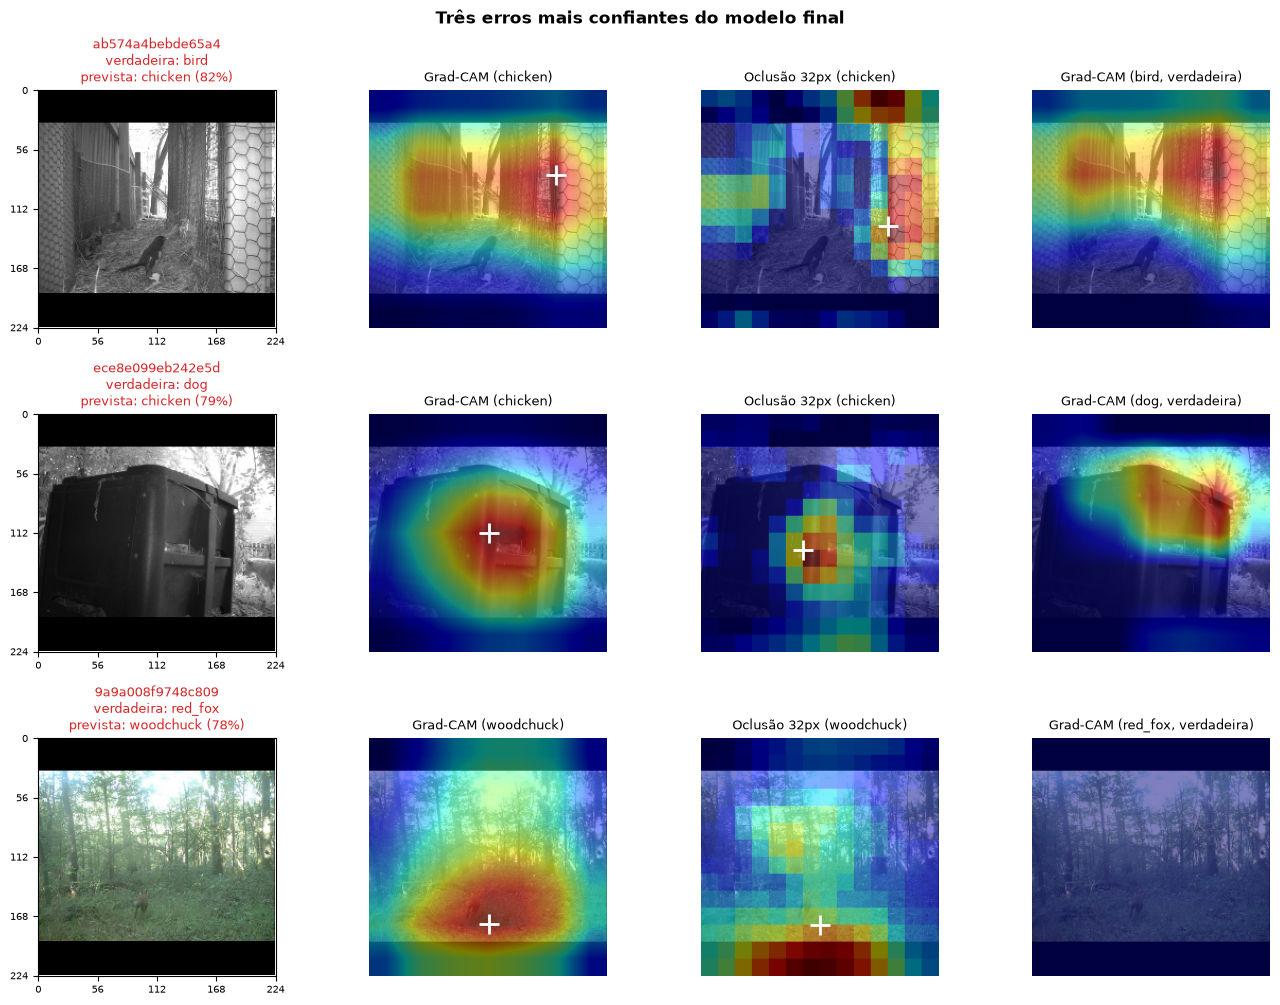

,image_id,verdadeira,prevista,confianca,p_verdadeira,croma_medio,tam_original,escala_p/224,gradcam_area50,gradcam_pico,gradcam_bbox50,oclusao_area50,oclusao_pico,oclusao_bbox50,oclusao_queda_max
0,ab574a4bebde65a4,bird,chicken,0.821,0.061,0.00,512x367,0.438,0.341,"(175, 80)","(224, 124)",0.170,"(176, 128)","(80, 129)",0.059
1,ece8e099eb242e5d,dog,chicken,0.793,0.016,0.00,512x367,0.438,0.278,"(112, 112)","(141, 121)",0.139,"(96, 128)","(64, 64)",0.126
2,9a9a008f9748c809,red_fox,woodchuck,0.778,0.002,26.28,512x367,0.438,0.317,"(112, 175)","(173, 150)",0.297,"(112, 176)","(176, 128)",0.308


In [39]:
idx_erros = selecionar_erros(probs_teste, y_teste, k=3)   # ou escolha à mão: idx_erros = [i, j, k]
fig, tab_erros = galeria(ids_teste[idx_erros], y_teste[idx_erros], modelo_final, RAIZ_TEST, DEVICE,
                         le.classes_, transform_val, titulo='Três erros mais confiantes do modelo final',
                         com_classe_verdadeira=True)
fig.savefig('figuras/parte3_erros.png', dpi=150, bbox_inches='tight')
plt.show()
tab_erros.round(3)

### Diagnóstico dos erros

*(Leitura visual das figuras; os pixels são do quadro 224×224 já com letterbox, uma foto 512×367 vira 224×160 com faixa preta de ≈ 32 px acima e abaixo, e os picos têm incerteza de ±16 px. Tamanhos de animal são estimados a olho nos eixos.)*

**Erro 1: `ab574a4bebde65a4`, bird → chicken, confiança 82% (p(bird) = 0,061).**
Foto infravermelha (croma 0,0). Galinheiro com tela hexagonal dos dois lados e um poste. O animal parece ser a massa escura no chão, centro-direita, de ≈ 40×25 px. Grad-CAM com pico em (175, 80) e oclusão em (176, 128) caem na tela e no poste do lado direito, não no animal; a queda máxima por janela é de só 5,9 pontos (a menor entre os erros), ou seja, a decisão está espalhada. O Grad-CAM da classe verdadeira (`bird`) também cai nas cercas.
*Diagnóstico:* foto noturna, animal pequeno; o modelo responde `chicken` pelo **cenário** (galinheiro com tela hexagonal), não pelo bicho.

**Erro 2: `ece8e099eb242e5d`, dog → chicken, confiança 79% (p(dog) = 0,016).**
Foto infravermelha (croma 0,0), dominada por um contêiner escuro no centro. Os dois mapas coincidem (picos em (112, 112) e (96, 128), a ≈ 22 px um do outro) e estão **no contêiner**; a mancha da oclusão tem ≈ 64×64 px e a queda máxima é de 12,6 pontos. Não consegui localizar um cão nítido; o Grad-CAM da classe verdadeira se concentra na quina superior direita do contêiner *(confirmar na imagem original se há um cão parcialmente visível)*.
*Diagnóstico:* foto noturna em que o animal é pequeno ou está cortado e o fundo domina; o modelo vê estrutura humana (contêiner) e diz `chicken`. É a mesma imagem que também era erro com o modelo anterior, ou seja, é um caso difícil de forma consistente.

**Erro 3: `9a9a008f9748c809`, red_fox → woodchuck, confiança 78% (p(red_fox) = 0,002).**
Única foto diurna (croma 26,3), mata aberta com chão de folhas. A raposa é um vulto minúsculo no canto inferior esquerdo, de ≈ 20×15 px *(confirmar na imagem)*. Os dois mapas coincidem (picos em (112, 175) e (112, 176)) e cobrem uma faixa larga do chão (a mancha da oclusão tem ≈ 176×128 px); a queda máxima de 30,8 pontos é a maior dos três erros. O Grad-CAM da classe verdadeira (`red_fox`) fica praticamente em branco.
*Diagnóstico:* animal minúsculo e fora das regiões ativas; a previsão `woodchuck` vem da **textura do chão aberto**, não do animal.

**Padrão entre os três**
- **Animal pequeno, mapas no cenário** (tela, contêiner, chão): em nenhum dos três o pico dos mapas cai sobre o animal. Dois dos três erros viram `chicken`, o que sugere que cenas com estruturas humanas funcionam como atrator para essa classe *(hipótese, n = 3)*.
- **Erros confiantes:** 78–82% de confiança com p(classe verdadeira) ≤ 0,061. Isso tem relação direta com a pergunta da capivara.
- **Noite:** 2 dos 3 erros são infravermelhos, mas 3 dos 5 acertos também; com tão poucos casos não dá para dizer que a noite explica os erros.
- **Concordância entre mapas:** nos erros 2 e 3 Grad-CAM e oclusão coincidem (1 a 22 px), no erro 1 ficam a ≈ 48 px. Quando coincidem, o mapa não está apontando para o animal.
- `*_bbox50` descreve o trecho que sustenta a decisão, não o tamanho do animal (no Grad-CAM costuma ocupar a largura toda); o tamanho do animal acima vem da leitura dos eixos.

In [40]:
def frases(tab):
    for _, r in tab.iterrows():
        periodo = 'noturna (IR)' if r.croma_medio < 5 else 'diurna'
        w, h = r.oclusao_bbox50
        print(f"{r.image_id}: {r.verdadeira} → {r.prevista} ({r.confianca:.0%}; p(verdadeira)={r.p_verdadeira:.3f}), foto {periodo}, "
              f"original {r.tam_original}; mancha da oclusão ≈ {w}×{h}px em 224, pico da oclusão {r.oclusao_pico}, "
              f"pico do Grad-CAM {r.gradcam_pico}, queda máx por janela {r.oclusao_queda_max:.0%}")

def agregados(tab):
    dist = tab.apply(lambda r: np.hypot(r.gradcam_pico[0] - r.oclusao_pico[0], r.gradcam_pico[1] - r.oclusao_pico[1]), axis=1)
    return {'noturnas': f"{int((tab.croma_medio < 5).sum())}/{len(tab)}",
            'queda_max média': f"{tab.oclusao_queda_max.mean():.0%}",
            'dist. Grad-CAM↔oclusão (px)': f"{dist.min():.0f}–{dist.max():.0f}"}

frases(tab_erros)
print(agregados(tab_erros))

ab574a4bebde65a4: bird → chicken (82%; p(verdadeira)=0.061), foto noturna (IR), original 512x367; mancha da oclusão ≈ 80×129px em 224, pico da oclusão (176, 128), pico do Grad-CAM (175, 80), queda máx por janela 6%
ece8e099eb242e5d: dog → chicken (79%; p(verdadeira)=0.016), foto noturna (IR), original 512x367; mancha da oclusão ≈ 64×64px em 224, pico da oclusão (96, 128), pico do Grad-CAM (112, 112), queda máx por janela 13%
9a9a008f9748c809: red_fox → woodchuck (78%; p(verdadeira)=0.002), foto diurna, original 512x367; mancha da oclusão ≈ 176×128px em 224, pico da oclusão (112, 176), pico do Grad-CAM (112, 175), queda máx por janela 31%
{'noturnas': '2/3', 'queda_max média': '16%', 'dist. Grad-CAM↔oclusão (px)': '1–48'}


## 2. A pergunta inversa: cinco acertos

Cinco acertos **sorteados** (semente fixa, classes distintas), e não os mais confiantes, para não escolher só os casos bonitos. A pergunta é se o modelo acertou olhando para o animal ou para o fundo.

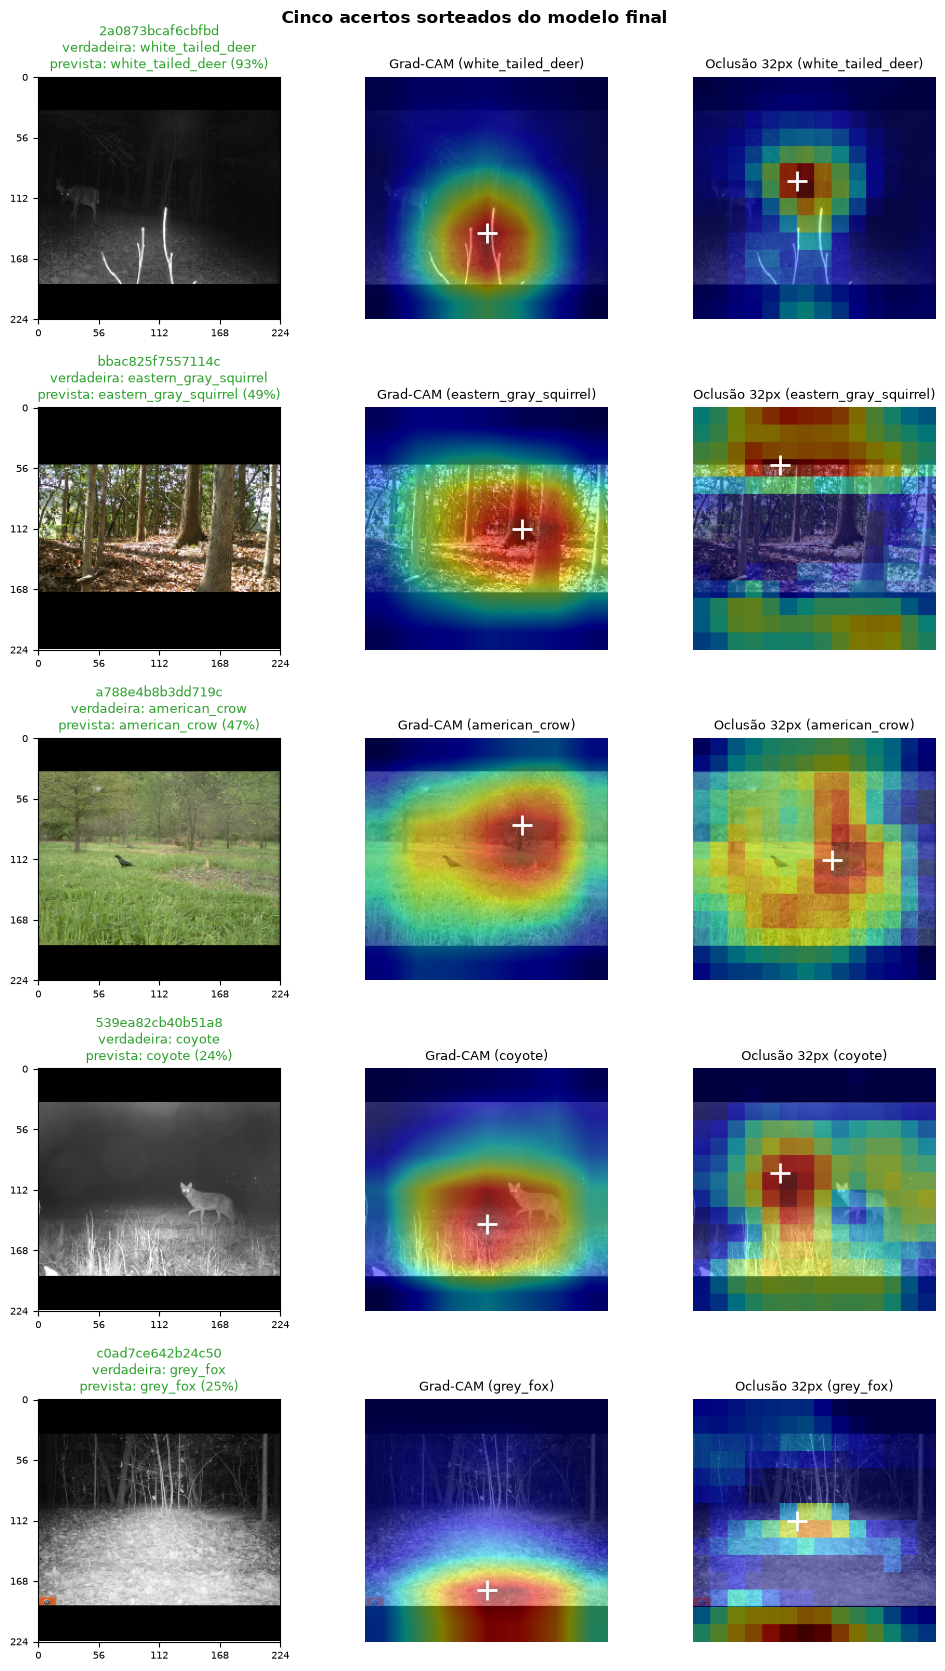

,image_id,verdadeira,prevista,confianca,p_verdadeira,croma_medio,tam_original,escala_p/224,gradcam_area50,gradcam_pico,gradcam_bbox50,oclusao_area50,oclusao_pico,oclusao_bbox50,oclusao_queda_max
0,2a0873bcaf6cbfbd,white_tailed_deer,white_tailed_deer,0.927,0.927,0.000,512x367,0.438,0.193,"(112, 144)","(107, 96)",0.140,"(96, 96)","(80, 80)",0.276
1,bbac825f7557114c,eastern_gray_squirrel,eastern_gray_squirrel,0.485,0.485,39.538,512x270,0.438,0.357,"(144, 112)","(177, 116)",0.134,"(80, 53)","(192, 11)",0.097
2,a788e4b8b3dd719c,american_crow,american_crow,0.472,0.472,56.458,512x367,0.438,0.342,"(144, 80)","(182, 130)",0.343,"(128, 112)","(192, 161)",0.172
3,539ea82cb40b51a8,coyote,coyote,0.242,0.242,0.000,512x367,0.438,0.282,"(112, 143)","(162, 107)",0.308,"(80, 96)","(192, 144)",0.105
4,c0ad7ce642b24c50,grey_fox,grey_fox,0.246,0.246,0.488,512x364,0.438,0.131,"(112, 176)","(157, 39)",0.140,"(96, 112)","(80, 48)",0.072


In [41]:
idx_acertos = selecionar_acertos(probs_teste, y_teste, k=5, seed=0)
fig, tab_acertos = galeria(ids_teste[idx_acertos], y_teste[idx_acertos], modelo_final, RAIZ_TEST, DEVICE,
                           le.classes_, transform_val, titulo='Cinco acertos sorteados do modelo final')
fig.savefig('figuras/parte3_acertos.png', dpi=150, bbox_inches='tight')
plt.show()
tab_acertos.round(3)

### Veredito dos acertos

*(Leitura visual; conferir cada linha nas figuras.)*

| id | classe (confiança, período) | pico Grad-CAM | pico oclusão | olhou para… |
|---|---|---|---|---|
| `2a0873bcaf6cbfbd` | white_tailed_deer (93%, noite) | (112, 144) | (96, 96) | **Misto.** O cervo está à esquerda (x ≈ 50–70); o pico da oclusão cai ≈ 30 px à direita dele, bem perto, e é o mapa mais concentrado (mancha 80×80, queda 27,6 pontos). O Grad-CAM vai para galhos claros abaixo. |
| `bbac825f7557114c` | eastern_gray_squirrel (49%, dia) | (144, 112) | (80, 53) | **Fundo.** Mata com troncos; o Grad-CAM cai num tronco e a oclusão numa faixa estreita (192×11) no topo da foto. Não vejo o esquilo sob os mapas. |
| `a788e4b8b3dd719c` | american_crow (47%, dia) | (144, 80) | (128, 112) | **Fundo.** O corvo é pequeno e fica à esquerda do centro; os picos estão nas árvores e na grama. Mancha difusa de 192×161 px. |
| `539ea82cb40b51a8` | coyote (24%, noite) | (112, 143) | (80, 96) | **Fundo.** O coiote está à direita (x ≈ 170–205); os picos ficam no capim e à esquerda dele. |
| `c0ad7ce642b24c50` | grey_fox (25%, noite) | (112, 176) | (96, 112) | **Fundo/incerto.** Não localizo o animal. O Grad-CAM cai na borda inferior da foto, perto do marcador laranja do canto inferior esquerdo. |

**Conclusão.** Em apenas **1 dos 5** acertos os mapas caem perto do animal (cervo, e só o de oclusão); em **4 dos 5** o pico cai no fundo ou não dá para dizer onde está o animal. Os acertos são frágeis: 4 dos 5 têm confiança de só 24–49%. Isso é compatível com um modelo que usa o cenário, o que casa com as câmeras repetidas entre train e test. A amostra é pequena (5 casos, 1 seed de sorteio), então ilustra e não estima a taxa de acertos "pelo motivo certo".

**Hipótese a testar: o letterbox.** Em vários casos (esquilo, grey_fox) a oclusão é alta justamente nas faixas pretas. Como o enunciado diz que as proporções variam por câmera, a faixa pode revelar a câmera. Parte desse efeito pode ser artefato da oclusão (cobrir a faixa preta com a média cria bordas novas), então só se sustenta com um teste, por exemplo oclusão com a mesma cor da faixa, ou treinar com padding aleatório.

**Ressalvas.**
- Não há caixas dos animais no pacote, então "animal vs fundo" é **visual**, não medido. `area50`, `pico` e `bbox50` apoiam a leitura, mas não a substituem.
- Mapa de saliência mostra onde o modelo é *sensível*, não prova causalidade; a oclusão é a mais próxima disso. O Grad-CAM de 7×7 pode borrar um animal pequeno para o fundo vizinho.
- O marcador laranja (resquício da faixa da câmera) aparece no canto inferior esquerdo de algumas imagens, inclusive no grey_fox. É um identificador de câmera; vale checar no `train` se ocorre mais em alguma classe, porque poderia virar atalho.

In [42]:
frases(tab_acertos)
print(agregados(tab_acertos))

2a0873bcaf6cbfbd: white_tailed_deer → white_tailed_deer (93%; p(verdadeira)=0.927), foto noturna (IR), original 512x367; mancha da oclusão ≈ 80×80px em 224, pico da oclusão (96, 96), pico do Grad-CAM (112, 144), queda máx por janela 28%
bbac825f7557114c: eastern_gray_squirrel → eastern_gray_squirrel (49%; p(verdadeira)=0.485), foto diurna, original 512x270; mancha da oclusão ≈ 192×11px em 224, pico da oclusão (80, 53), pico do Grad-CAM (144, 112), queda máx por janela 10%
a788e4b8b3dd719c: american_crow → american_crow (47%; p(verdadeira)=0.472), foto diurna, original 512x367; mancha da oclusão ≈ 192×161px em 224, pico da oclusão (128, 112), pico do Grad-CAM (144, 80), queda máx por janela 17%
539ea82cb40b51a8: coyote → coyote (24%; p(verdadeira)=0.242), foto noturna (IR), original 512x367; mancha da oclusão ≈ 192×144px em 224, pico da oclusão (80, 96), pico do Grad-CAM (112, 143), queda máx por janela 11%
c0ad7ce642b24c50: grey_fox → grey_fox (25%; p(verdadeira)=0.246), foto noturna (